<img width=200 height=200 src = "iris.png" >


In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

In [10]:
iris=load_iris(as_frame=True)
# df=iris['data']
# df.head()
iris

df=iris['frame']
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [12]:
df['target'].unique()

array([0, 1, 2])

In [13]:
df.shape

(150, 5)

In [14]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [15]:
df['target'].value_counts()

target
0    50
1    50
2    50
Name: count, dtype: int64

In [17]:
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [19]:
print(iris.keys())

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


### Data Visualization

<Axes: xlabel='sepal length (cm)', ylabel='sepal width (cm)'>

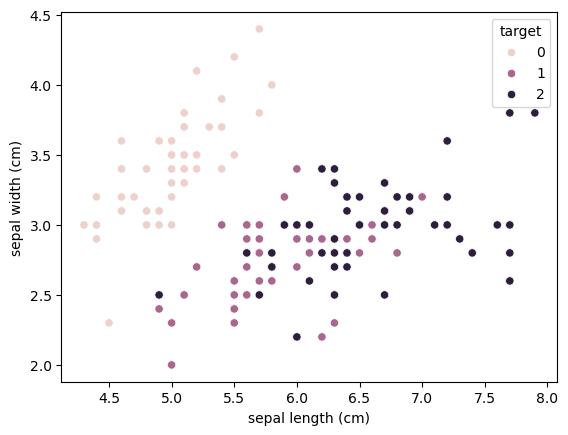

In [23]:
sns.scatterplot(df, x="sepal length (cm)", y= "sepal width (cm)",hue="target")

In [24]:
df['target_name']=df['target'].map({
    0 : "setosa",
    1 : 'versicolor',
    2 : "virginica"
})

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


<Axes: xlabel='sepal length (cm)', ylabel='sepal width (cm)'>

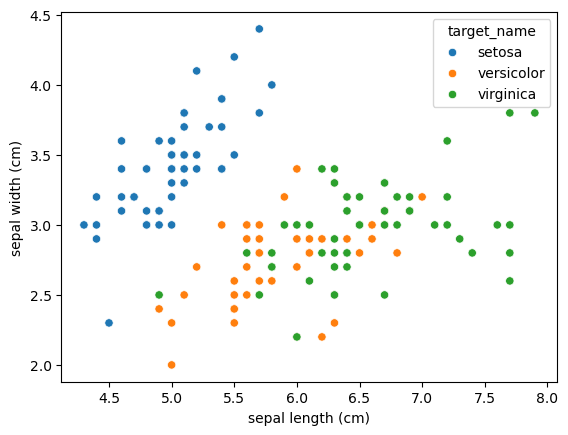

In [25]:
sns.scatterplot(df, x="sepal length (cm)", y= "sepal width (cm)",hue="target_name")

<Axes: xlabel='petal length (cm)', ylabel='petal width (cm)'>

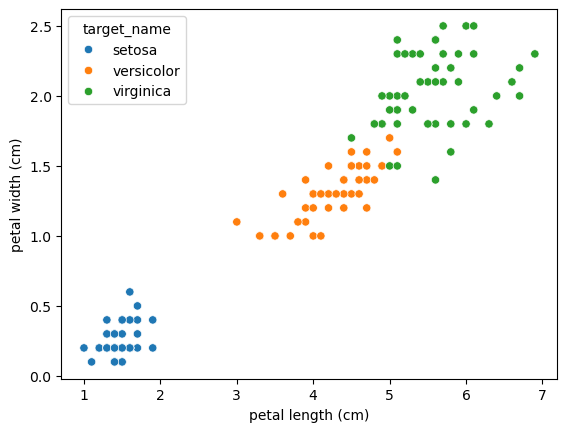

In [26]:
sns.scatterplot(df, x="petal length (cm)", y= "petal width (cm)",hue="target_name")

In [27]:
X = df[["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)"]]
y = df["target"]
X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [28]:
from sklearn.model_selection import train_test_split 
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.3, random_state=58)

In [35]:
from sklearn.linear_model import LogisticRegression

model=LogisticRegression(max_iter=200)
model.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


In [36]:
model.score(X_test,y_test)

0.9555555555555556

In [37]:
y_pred=model.predict(X_test)

In [38]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test,y_pred)

0.9555555555555556

In [39]:
y_pred[:10]

[1, 1, 2, 1, 0, 1, 0, 2, 1, 2]

In [41]:
y_test[:10].tolist()

[1, 1, 2, 1, 0, 1, 0, 1, 1, 2]

In [42]:
from sklearn.metrics import classification_report

report= classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       0.95      0.95      0.95        19
           2       0.93      0.93      0.93        15

    accuracy                           0.96        45
   macro avg       0.96      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



In [43]:
from sklearn.metrics import confusion_matrix

cm=confusion_matrix(y_test,y_pred)
cm

array([[11,  0,  0],
       [ 0, 18,  1],
       [ 0,  1, 14]])

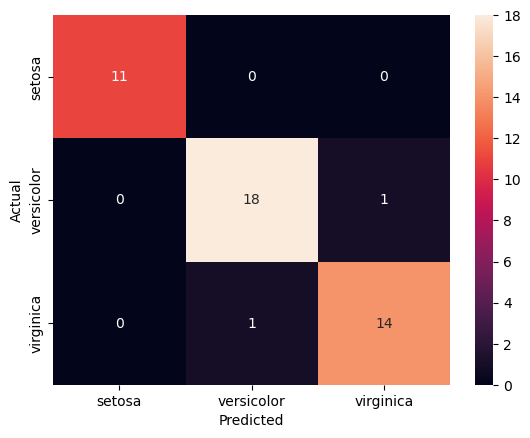

In [49]:
classes=df['target_name'].unique().tolist()
sns.heatmap(cm,annot=True,xticklabels=classes,yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [46]:
classes=df['target_name'].unique().tolist()
classes

['setosa', 'versicolor', 'virginica']